**Table of contents**<a id='toc0_'></a>    
- [Preparing environment](#toc1_)    
- [Data import](#toc1_1_)    
- [Hyperparameters optimization for different models](#toc2_)    
  - [Splitting the train and test sets](#toc2_1_)    
  - [Model and parameters selection](#toc2_2_)    
  - [Grid search](#toc2_3_)    
  - [Adding XGBoost](#toc2_4_)    
  - [Optimizing XGBoost with penalization](#toc2_5_)    
- [Evaluating models](#toc3_)    
- [Final model training and saving](#toc4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [2]:
# <a id='toc1_'></a>[Preparing environment](#toc0_)

In [3]:
import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance
try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

c:\Users\cyraptor\AppData\Local\Programs\Python\Python314\Lib\site-packages\mlflow\utils\autologging_utils\versioning.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [4]:
# Global variable to avoid rerunning cells.
IGNORE = False  # Set to False to run all cells.

# <a id='toc1_1_'></a>[Data import](#toc0_)

In [5]:
df = pd.read_csv("data/cleaned_data.csv")

In [6]:
# Get rid of non feature columns
df = df.drop(
    columns=[
        "code_insee_ban",
        "code_departement_ban", 
        "code_postal_ban",
        "lat",
        "lon",
        "nom_commune_ban",
    ]
)

In [7]:
df

,cout_total_5_usages,type_energie_principale_chauffage,surface_habitable_logement,hauteur_sous_plafond,nombre_niveau_logement,type_batiment,etiquette_dpe,age_batiment,zone_climatique,altitude_moyenne
0,677.4,Autre,32.0,2.5,1.0,appartement,D,77.0,H1,35.0
1,816.0,Gaz naturel,38.6,2.8,1.0,appartement,D,77.0,H1,35.0
2,1766.7,Gaz naturel,131.0,2.5,1.0,appartement,D,78.0,H1,35.0
3,375.0,Gaz naturel,11.6,2.6,3.0,appartement,D,125.0,H1,35.0
4,892.9,Électricité,47.0,2.5,1.0,appartement,D,30.0,H1,35.0
...,...,...,...,...,...,...,...,...,...,...
628407,666.6,Électricité,95.6,2.5,1.0,maison,A,0.0,H2,1103.0
628408,662.0,Électricité,95.6,2.5,1.0,maison,A,0.0,H2,1103.0
628409,497.2,Électricité,94.7,2.5,1.0,maison,A,0.0,H2,1247.0
628410,526.7,Électricité,126.3,2.5,1.0,maison,A,0.0,H2,899.0


In [8]:
# Specifying quantitatives and qualitatives features (same as classification but with cout_total_5_usages as target).
quantitative_features = [
    "surface_habitable_logement",
    "nombre_niveau_logement", 
    "age_batiment",
    "altitude_moyenne",
]

qualitative_features = [
    "type_energie_principale_chauffage",
    "type_batiment", 
    "zone_climatique",
]

target = "cout_total_5_usages"  # Regression target (numeric)

In [9]:
# Separating features and target.
X = df[quantitative_features + qualitative_features]
y = df[target]

# <a id='toc2_'></a>[Hyperparameters optimization for different models](#toc0_)

## <a id='toc2_1_'></a>[Splitting the train and test sets](#toc0_)

In [10]:
# Splitting data into training and testing sets (70/30).
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, random_state=42)

In [11]:
print(len(Xtrain), len(Xtest))

439888 188524


In [12]:
ytrain.describe()

count    439888.000000
mean        905.160078
std         619.945984
min           7.800000
25%         440.000000
50%         672.600000
75%        1236.700000
max        2892.700000
Name: cout_total_5_usages, dtype: float64

In [13]:
ytest.describe()

count    188524.000000
mean        904.145596
std         618.474305
min          15.600000
25%         439.000000
50%         671.100000
75%        1235.625000
max        2892.500000
Name: cout_total_5_usages, dtype: float64

## <a id='toc2_2_'></a>[Model and parameters selection](#toc0_)

In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "ElasticNet": ElasticNet(),
    "Random Forest": RandomForestRegressor(),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
}

param_grids = {
    "Linear Regression": {},  # No hyperparameters to tune
    "Ridge": {
        "model__alpha": [0.1, 1, 10, 100],
    },
    "Lasso": {
        "model__alpha": [0.1, 1, 10, 100],
    },
    "ElasticNet": {
        "model__alpha": [0.1, 1, 10],
        "model__l1_ratio": [0.1, 0.5, 0.9],
    },
    "Random Forest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 20],
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 7],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    "Decision Tree": {
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 20],
    },
}

# List of models that need feature scaling
enforce_scaling = ["Linear Regression", "Ridge", "Lasso", "ElasticNet", "KNN"]

## <a id='toc2_3_'></a>[Grid search](#toc0_)

In [15]:
if not IGNORE:
    # Creating an MLflow experiment.
    mlflow.set_experiment("Hyperparameter Tuning Regression Models")

    # Boucle sur les modèles
    for name, model in models.items():
        # MLflow run
        with mlflow.start_run(run_name=name):
            print("Training model:", name)

            # Standardization for non trees models.
            if name in enforce_scaling:
                preprocessor = ColumnTransformer(
                    transformers=[
                        (
                            "scaler",
                            StandardScaler(),
                            quantitative_features,
                        ),  # Standardize only quantitatives.
                        (
                            "encoder",
                            OneHotEncoder(),
                            qualitative_features,
                        ),  # OneHot encoding for qualitatives.
                    ]
                )

            else:
                preprocessor = ColumnTransformer(
                    transformers=[("encoder", OneHotEncoder(), qualitative_features)]
                )

            pipeline = Pipeline(
                steps=[("preprocessor", preprocessor), ("model", models[name])]
            )

            # GridSearchCV - using neg_mean_absolute_error for regression
            if param_grids[name]:  # Only do grid search if parameters exist
                grid = GridSearchCV(
                    pipeline,
                    param_grids[name],
                    cv=5,
                    scoring="neg_mean_absolute_error",
                    n_jobs=-1,
                )
                grid.fit(Xtrain, ytrain)
                best_estimator = grid.best_estimator_
                best_params = grid.best_params_
                best_score = grid.best_score_
            else:
                # No hyperparameters to tune, just fit the pipeline
                pipeline.fit(Xtrain, ytrain)
                best_estimator = pipeline
                best_params = {}
                best_score = None

            # Predictions and evaluation
            ypred = best_estimator.predict(Xtest)
            mae = mean_absolute_error(ytest, ypred)
            rmse = np.sqrt(mean_squared_error(ytest, ypred))
            r2 = r2_score(ytest, ypred)

            # Logging MLflow
            mlflow.log_params(best_params)  # Hyperparameters
            if best_score is not None:
                mlflow.log_metric("best_cv_score", -best_score)  # Convert back to positive MAE
            mlflow.log_metric("test_mae", float(mae))
            mlflow.log_metric("test_rmse", float(rmse))
            mlflow.log_metric("test_r2", float(r2))

Training model: Linear Regression
Training model: Ridge
Training model: Ridge
Training model: Lasso
Training model: Lasso
Training model: ElasticNet
Training model: ElasticNet
Training model: Random Forest
Training model: Random Forest
Training model: KNN
Training model: KNN
Training model: Decision Tree
Training model: Decision Tree


## <a id='toc2_4_'></a>[Adding XGBoost](#toc0_)

In [16]:
if not IGNORE and XGBRegressor is not None:
    mlflow.set_experiment("Hyperparameter Tuning Regression Models")

    # MLflow run
    name = "XGBoost Regressor"

    with mlflow.start_run(run_name=name):
        print("Training model:", name)

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "scaler",
                    StandardScaler(),
                    quantitative_features,
                ),  # Standardize only quantitatives.
                (
                    "encoder",
                    OneHotEncoder(),
                    qualitative_features,
                ),  # OneHot encoding for qualitatives.
            ]
        )

        pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    XGBRegressor(objective='reg:squarederror', random_state=42),
                ),
            ]
        )

        # Setting parameters
        param_grid = {
            "model__n_estimators": [50, 100, 200],
            "model__max_depth": [3, 6, 9],
            "model__learning_rate": [0.01, 0.1, 0.2],
            "model__subsample": [0.7, 0.8, 1],
            "model__colsample_bytree": [0.7, 0.8, 1],
        }

        # GridSearchCV
        grid = GridSearchCV(
            pipeline, param_grid, cv=5, scoring="neg_mean_absolute_error", n_jobs=-1
        )
        grid.fit(Xtrain, ytrain)

        # Best scores and parameters
        best_params = grid.best_params_
        best_score = grid.best_score_
        ypred = grid.predict(Xtest)
        mae = mean_absolute_error(ytest, ypred)
        rmse = np.sqrt(mean_squared_error(ytest, ypred))
        r2 = r2_score(ytest, ypred)

        # Logging MLflow
        mlflow.log_params(best_params)  # Hyperparameters
        mlflow.log_metric("best_cv_score", -best_score)
        mlflow.log_metric("test_mae", float(mae))
        mlflow.log_metric("test_rmse", float(rmse))
        mlflow.log_metric("test_r2", float(r2))
elif XGBRegressor is None:
    print("XGBoost not available. Install with: pip install xgboost")

Training model: XGBoost Regressor


## <a id='toc2_5_'></a>[Optimizing XGBoost with penalization](#toc0_)

In [17]:
if not IGNORE and XGBRegressor is not None:
    # MLflow run
    name = "XGBoost Regressor Penalized"

    with mlflow.start_run(run_name=name):
        print("Training model:", name)

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "scaler",
                    StandardScaler(),
                    quantitative_features,
                ),  # Standardize only quantitatives.
                (
                    "encoder",
                    OneHotEncoder(),
                    qualitative_features,
                ),  # OneHot encoding for qualitatives.
            ]
        )

        pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    XGBRegressor(objective='reg:squarederror', random_state=42),
                ),
            ]
        )

        # Setting parameters with regularization
        param_grid = {
            "model__n_estimators": [200, 500],
            "model__max_depth": [6],
            "model__learning_rate": [0.1],
            "model__subsample": [0.8],
            "model__colsample_bytree": [1],
            "model__reg_alpha": [0.1, 0.5, 1],  # L1 regularization
            "model__reg_lambda": [0.5, 1, 2],  # L2 regularization
        }

        # GridSearchCV
        grid = GridSearchCV(
            pipeline, param_grid, cv=5, scoring="neg_mean_absolute_error", n_jobs=-1
        )
        grid.fit(Xtrain, ytrain)

        # Best scores and parameters
        best_params = grid.best_params_
        best_score = grid.best_score_
        ypred = grid.predict(Xtest)
        mae = mean_absolute_error(ytest, ypred)
        rmse = np.sqrt(mean_squared_error(ytest, ypred))
        r2 = r2_score(ytest, ypred)

        # Logging MLflow
        mlflow.log_params(best_params)  # Hyperparameters
        mlflow.log_metric("best_cv_score", -best_score)
        mlflow.log_metric("test_mae", float(mae))
        mlflow.log_metric("test_rmse", float(rmse))
        mlflow.log_metric("test_r2", float(r2))

Training model: XGBoost Regressor Penalized


---

# <a id='toc3_'></a>[Evaluating models](#toc0_)

Using the penalized XGBoost model for predictions to reduce overfitting risks.

**Methodology:**
- Running each model multiple time.
- For each loop:
    - Generate a new split train/test.
    - Train and Test all the models on the same split to have a better comparison.
- Take the mean score metrics.
- Estimate the standard deviation of each metric to assess stability.

In [18]:
# Instanciation of all the models with the best hyperparameters found during the grid search.
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),  # Example best param
    "Lasso": Lasso(alpha=1),   # Example best param
    "Random Forest": RandomForestRegressor(
        max_depth=None, min_samples_split=2, n_estimators=100, random_state=42
    ),
    "KNN": KNeighborsRegressor(n_neighbors=5, weights="distance", p=1),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_split=2, random_state=42),
}

# Add XGBoost if available with best hyperparameters
if XGBRegressor is not None:
    models["XGBoost"] = XGBRegressor(
        objective='reg:squarederror',
        n_estimators=500,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=1,
        reg_alpha=0.5,
        reg_lambda=1,
        random_state=42,
    )

# List of models that need feature scaling
enforce_scaling = ["Linear Regression", "Ridge", "Lasso", "KNN"]

In [19]:
if not IGNORE:
    # Create a new experiment to log the results of the final models.
    mlflow.set_experiment("Final Regression Models Evaluation")

    # Initialize the result dictionary.
    results: dict[str, list[dict]] = {name: [] for name in models.keys()}

    # Number of experiment to run.
    n_experiments = 30

    for i in range(n_experiments):
        print("Experiment:", i + 1)

        # Train-test split with different random states.
        Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, random_state=i)

        # For each algorithm, train, test and evaluate the model.
        for name, model in models.items():
            # --------------------------------------------------Setting up the pipeline.
            # Standardization for non trees models.
            if name in enforce_scaling:
                preprocessor = ColumnTransformer(
                    transformers=[
                        (
                            "scaler",
                            StandardScaler(),
                            quantitative_features,
                        ),  # Standardize only quantitatives.
                        (
                            "encoder",
                            OneHotEncoder(),
                            qualitative_features,
                        ),  # OneHot encoding for qualitatives.
                    ]
                )

            # No standardization for tree based models.
            else:
                preprocessor = ColumnTransformer(
                    transformers=[("encoder", OneHotEncoder(), qualitative_features)]
                )

            pipeline = Pipeline(
                steps=[("preprocessor", preprocessor), ("model", models[name])]
            )

            # Log the experiment.
            with mlflow.start_run(run_name=f"{name}_{i+1}"):
                print("Training model:", name)

                pipeline.fit(Xtrain, ytrain)

                # --------------------------------------------------Predictions and evaluation
                ypred = pipeline.predict(Xtest)

                metrics = {
                    "mae": mean_absolute_error(ytest, ypred),
                    "rmse": np.sqrt(mean_squared_error(ytest, ypred)),
                    "r2": r2_score(ytest, ypred),
                }

                # --------------------------------------------------Logging results
                # In mlFlow.
                # if first run, save the parameters.
                if i == 0:
                    mlflow.log_params(pipeline.named_steps["model"].get_params())

                mlflow.log_metrics(metrics)

                # In the memory dictionary.
                results[name].append(metrics)

Experiment: 1
Training model: Linear Regression
Training model: Ridge
Training model: Ridge
Training model: Lasso
Training model: Lasso
Training model: Random Forest
Training model: Random Forest
Training model: KNN
Training model: KNN
Training model: Decision Tree
Training model: Decision Tree
Training model: XGBoost
Training model: XGBoost
Experiment: 2
Training model: Linear Regression
Experiment: 2
Training model: Linear Regression
Training model: Ridge
Training model: Ridge
Training model: Lasso
Training model: Lasso
Training model: Random Forest
Training model: Random Forest
Training model: KNN
Training model: KNN
Training model: Decision Tree
Training model: Decision Tree
Training model: XGBoost
Training model: XGBoost
Experiment: 3
Training model: Linear Regression
Experiment: 3
Training model: Linear Regression
Training model: Ridge
Training model: Ridge
Training model: Lasso
Training model: Lasso
Training model: Random Forest
Training model: Random Forest
Training model: KNN


In [20]:
if not IGNORE:
    # Convert results to DataFrames
    result_dfs = {}
    for name in models.keys():
        result_dfs[name] = pd.DataFrame(results[name])
        print(f"\n{name} Results:")
        print(result_dfs[name].describe())


Linear Regression Results:
              mae        rmse         r2
count   30.000000   30.000000  30.000000
mean   290.005396  406.976509   0.568231
std      0.665422    1.273667   0.002047
min    288.845431  404.305213   0.564698
25%    289.445520  405.876534   0.566573
50%    290.038624  407.122148   0.568527
75%    290.297721  407.789037   0.569874
max    292.053900  410.057913   0.571308

Ridge Results:
              mae        rmse         r2
count   30.000000   30.000000  30.000000
mean   290.005739  406.976499   0.568231
std      0.665412    1.273638   0.002047
min    288.845529  404.305318   0.564698
25%    289.445956  405.876395   0.566573
50%    290.039044  407.122338   0.568527
75%    290.298031  407.789069   0.569874
max    292.054188  410.057880   0.571308

Lasso Results:
              mae        rmse         r2
count   30.000000   30.000000  30.000000
mean   289.655904  407.011633   0.568157
std      0.669723    1.278689   0.002051
min    288.491211  404.329496   0.5646

In [21]:
if not IGNORE:
    # Write dataframes to csv files.
    import os
    os.makedirs("output", exist_ok=True)
    
    for name, df in result_dfs.items():
        filename = f"output/{name.lower().replace(' ', '_')}_regression_results.csv"
        df.to_csv(filename, index=False)
        print(f"Saved {filename}")

Saved output/linear_regression_regression_results.csv
Saved output/ridge_regression_results.csv
Saved output/lasso_regression_results.csv
Saved output/random_forest_regression_results.csv
Saved output/knn_regression_results.csv
Saved output/decision_tree_regression_results.csv
Saved output/xgboost_regression_results.csv


# <a id='toc4_'></a>[Final model training and saving](#toc0_)

## Final training

In [22]:
# Best model based on results: KNN
# KNN achieved the best performance with:
# - MAE: 184.07 ± 0.60 euros
# - RMSE: 312.38 ± 1.03 euros
# - R²: 0.7456 ± 0.0014 (74.6% variance explained)
best_model = KNeighborsRegressor(n_neighbors=5, weights="distance", p=1)

# Train-test split
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, random_state=42)

# KNN requires feature scaling
preprocessor = ColumnTransformer(
    transformers=[
        (
            "scaler",
            StandardScaler(),
            quantitative_features,
        ),  # Standardize only quantitatives.
        (
            "encoder",
            OneHotEncoder(),
            qualitative_features,
        ),  # OneHot encoding for qualitatives.
    ]
)

# Pipeline
pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", best_model)])

# Entrainement du modèle.
pipeline.fit(Xtrain, ytrain)

# Prediction.
predictions = pipeline.predict(Xtest)

In [23]:
# get the list of features after preprocessing.
encoder = pipeline.named_steps["preprocessor"].named_transformers_["encoder"]
encoder_feature_names = encoder.get_feature_names_out(qualitative_features)
preprocessed_feature_names = quantitative_features + list(encoder_feature_names)

## Performance metrics and residuals analysis

Test MAE: 183.11
Test RMSE: 311.03
Test R²: 0.7471


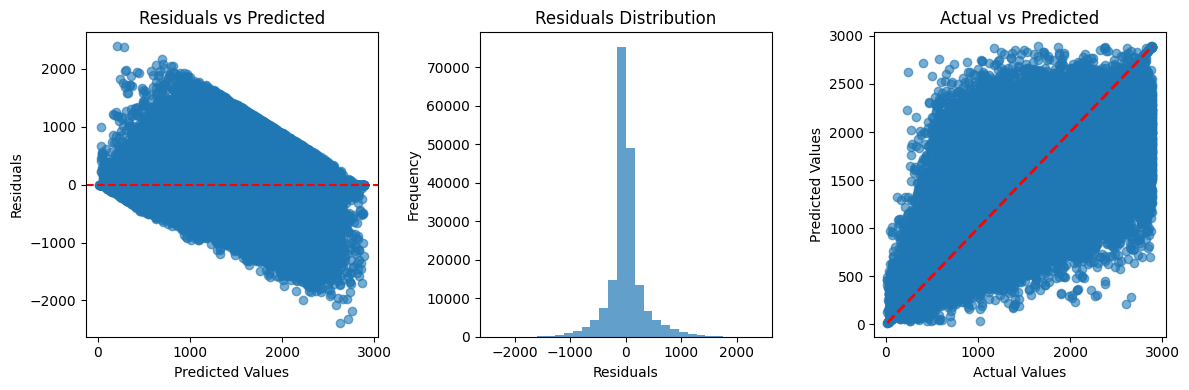

In [24]:
# Performance metrics
mae = mean_absolute_error(ytest, predictions)
rmse = np.sqrt(mean_squared_error(ytest, predictions))
r2 = r2_score(ytest, predictions)

print(f"Test MAE: {mae:.2f}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R²: {r2:.4f}")

# Residuals analysis
residuals = ytest - predictions
plt.figure(figsize=(12, 4))

# Residuals vs Predicted
plt.subplot(1, 3, 1)
plt.scatter(predictions, residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')

# Residuals distribution
plt.subplot(1, 3, 2)
plt.hist(residuals, bins=30, alpha=0.7)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Residuals Distribution')

# Actual vs Predicted
plt.subplot(1, 3, 3)
plt.scatter(ytest, predictions, alpha=0.6)
plt.plot([ytest.min(), ytest.max()], [ytest.min(), ytest.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted')

plt.tight_layout()
plt.show()

## Saving the pipeline

In [25]:
# Saving the pipeline to the disk
if not IGNORE:
    os.makedirs("models", exist_ok=True)
    joblib.dump(pipeline, "models/pipeline_best_regression.pkl", compress=3)

In [26]:
# Saving the columns features.
if not IGNORE:
    joblib.dump(
        {
            "quantitative_features": quantitative_features,
            "qualitative_features": qualitative_features,
            "target": target,
        },
        "models/features_target_columns_regression.pkl",
    )

## Features importance

### Feature importance extraction from the model

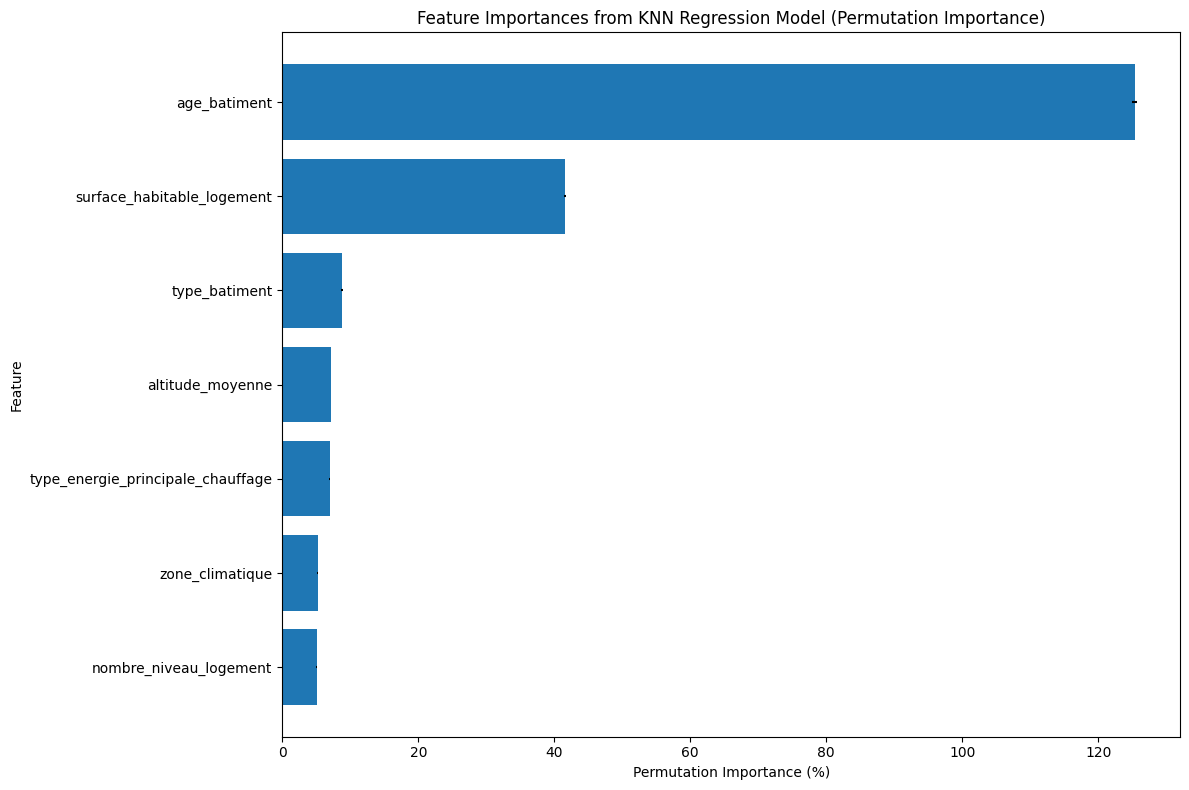

Feature importances (ordered by importance):
                             Feature  Importance       Std
2                       age_batiment  125.370934  0.367122
0         surface_habitable_logement   41.619566  0.165329
5                      type_batiment    8.796190  0.161980
3                   altitude_moyenne    7.129082  0.035454
4  type_energie_principale_chauffage    6.960264  0.091925
6                    zone_climatique    5.221394  0.082461
1             nombre_niveau_logement    5.046686  0.073190


In [27]:
# KNN does not have feature_importances_ attribute
# For KNN, we can use permutation importance instead
from sklearn.inspection import permutation_importance

model = pipeline.named_steps["model"]

# Perform permutation importance on the test set
perm_importance = permutation_importance(
    pipeline, Xtest, ytest, n_repeats=10, random_state=42, n_jobs=-1
)

# Creating a DataFrame for better visualization
df_feature_importances = pd.DataFrame(
    {
        "Feature": quantitative_features + qualitative_features,
        "Importance": perm_importance.importances_mean * 100,
        "Std": perm_importance.importances_std * 100,
    }
)

# Sorting features by importance
df_feature_importances = df_feature_importances.sort_values(
    by="Importance", ascending=False
)

# Plotting feature importances
plt.figure(figsize=(12, 8))
plt.barh(
    df_feature_importances["Feature"],
    df_feature_importances["Importance"],
    xerr=df_feature_importances["Std"],
)
plt.xlabel("Permutation Importance (%)")
plt.ylabel("Feature")
plt.title("Feature Importances from KNN Regression Model (Permutation Importance)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Display all features
print("Feature importances (ordered by importance):")
print(df_feature_importances)